# 01 — Business and Data Understanding
### Hotel Booking Behavior Segmentation Using Unsupervised Machine Learning

**CRISP-ML(Q) Phase:** Phase 1 — Business and Data Understanding

**Project stage:** 1 of 16

---

## 1. Objective

This notebook establishes the foundation for the entire project. By the end of this notebook we will have:

1. A clear, written statement of the business problem and the machine learning objective.
2. Defined success criteria — what "a good result" means for a project that has **no accuracy score to chase**, because it is unsupervised.
3. A full data dictionary describing every column in the raw dataset, in plain business language.
4. A first, high-level look at the dataset's shape and structure (full quality checks come in Notebook 02).
5. An explicit list of assumptions, constraints, risks, and known data limitations that will guide every later decision in this project.

We do **not** clean data, engineer features, or build any model in this notebook. This is a "look before you leap" step — a rushed jump into modeling is the single most common mistake in real-world ML projects, and CRISP-ML(Q) exists specifically to prevent that.

## 2. Business Context

### 2.1 Business Problem

The hotel company (data spans a **City Hotel** and a **Resort Hotel**) has years of historical booking records containing details about how each booking was made: how far in advance, how long the stay, how many guests, how it was modified, what it cost, how many special requests were made, and whether the guest had booked before.

Today, the hotel has **no systematic, data-driven way to group bookings by behavior**. Decisions about marketing, pricing, staffing, and guest experience are made without a clear picture of the different "types" of bookings the hotel actually receives.

### 2.2 Business Objective

Use the hotel's historical booking data to discover **naturally occurring groups of booking behavior**, so that different parts of the business (revenue management, marketing, front-desk operations, loyalty programs) can treat different types of bookings differently, instead of treating every booking the same way.

### 2.3 ML Objective

Apply **unsupervised clustering** to booking-level behavioral features to partition the bookings into a small number of statistically distinct, human-interpretable groups.

This is explicitly **not**:
- A cancellation prediction project (no classifier will be trained).
- A project with a labeled "correct" segment for each booking to predict against.

It **is**:
- A discovery task: let the structure in the data suggest the groups, rather than imposing groups in advance.

### 2.4 Success Criteria

Because there is no ground-truth label, "success" is judged along two tracks, and **both matter — neither alone is sufficient**:

| Track | What we check | Why it matters |
|---|---|---|
| Statistical validity | Silhouette score, Davies-Bouldin index, Calinski-Harabasz index, cluster stability across random seeds/subsamples | A clustering result that isn't mathematically well-separated isn't trustworthy, no matter how nice the story sounds |
| Business usefulness | Cluster sizes are large enough to act on, clusters differ in ways the hotel can actually respond to (value, loyalty, lead time, cancellation behavior), segment names are backed by evidence | A statistically "clean" clustering that produces meaningless or unusable groups doesn't help the business |

A specific numeric target (e.g. "silhouette must exceed 0.6") is **not** set in advance, because appropriate silhouette values vary heavily by dataset and dimensionality. Instead, Notebook 11 (model comparison) and Notebook 12 (hyperparameter tuning) will report the actual achieved values and compare candidate models against each other, transparently, once they are computed.

### 2.5 Business KPIs the Segments Should Help Explain

Once clusters are found (Notebook 13/14), each cluster will be profiled against these hotel-relevant KPIs:

- Average Daily Rate (ADR) and estimated booking value
- Average length of stay
- Repeat-guest percentage (loyalty indicator)
- Observed cancellation rate (profiled **after** clustering, never used as a clustering input)
- Average booking lead time
- Average number of special requests / parking spaces (service-intensity indicator)
- Booking-change frequency

### 2.6 Initial Assumptions

- Each row represents **one booking**, not one unique customer. The dataset has no customer ID, so the same person could appear in multiple rows with no way to link them (see Section 2.8, Data Limitations).
- `adr` (Average Daily Rate) is assumed to be a reasonable proxy for booking value, in the currency used by the source system, though it is not guaranteed to reflect final realized revenue (taxes, fees, discounts applied later, or cancellations are not necessarily reflected).
- Columns like `reservation_status` and `is_canceled` describe the **outcome** of a booking, not the behavior at the time it was made, and will be excluded from the clustering inputs themselves (Section 2.7 and formalized again in Notebook 06/13).
- The dataset is treated as a static historical snapshot for this phase of the project; no live data feed is assumed to exist yet.

### 2.7 Constraints

- No unique, verified customer identifier exists in the dataset — see Section 3 (Critical Conceptual Note) below.
- The project must run entirely from Jupyter notebooks executed in VS Code, without standalone `.py` implementation files.
- Clustering algorithms selected must remain computationally tractable on this dataset's size (approximately 119K rows) within a normal laptop/workstation environment.
- Outcome fields (`is_canceled`, `reservation_status`, `reservation_status_date`) must not be used as clustering inputs (see Section 2.6 and the dedicated leakage discussion in Notebook 06).

### 2.8 Risks

- **Booking-level vs. customer-level ambiguity**: without a customer ID, clusters describe *bookings*, and it is tempting — but not fully justified by the data — to describe them as *customers*. This project uses careful language throughout to avoid overstating what the data supports.
- **High-cardinality categorical variables** (`country`, `agent`, `company`) risk inflating dimensionality if encoded carelessly, which can degrade distance-based clustering. These will be handled deliberately in Notebook 06/07, not with default one-hot encoding.
- **Outlier-driven distortion**: features like `adr` and `lead_time` may contain legitimate but extreme values (premium bookings, very early group bookings) that could disproportionately influence distance-based clustering if not handled thoughtfully (Notebook 05).
- **Overfitting the narrative**: it is easy to *invent* a compelling story around clusters after seeing them. This project will justify every segment name with specific, calculated cluster statistics (Notebook 13/14), not general impressions.

### 2.9 Data Limitations

- No unique customer identifier — repeat-guest status is inferred only from the `is_repeated_guest`, `previous_cancellations`, and `previous_bookings_not_canceled` fields as recorded by the source hotel system, not verified against a customer database.
- `agent` and `company` have substantial missing data (checked with real numbers in Section 5 below) and cannot be assumed missing-at-random without investigation.
- The dataset is a historical snapshot; it does not necessarily reflect current market conditions, current pricing, or current guest behavior.

## 3. Critical Conceptual Note: Booking-Level, Not Customer-Level

This dataset contains **one row per booking**, not one row per unique customer, and there is **no customer ID column**. This has a direct consequence for how we must describe our results:

- We are performing **Hotel Booking Behavior Segmentation** — this is the project's formal name and the terminology used throughout.
- The resulting clusters will be described as **booking / customer behavior segments**, with the understanding that:
  - A single real customer could contribute multiple bookings, possibly landing in different segments across different stays.
  - `is_repeated_guest`, `previous_cancellations`, and `previous_bookings_not_canceled` give us a *signal* about repeat behavior, as recorded by the hotel's system at the time of that booking — but they are not a verified, deduplicated customer history.

We will **not** claim that "Cluster 3 contains 4,200 customers." We will say "Cluster 3 contains 4,200 bookings that share a common behavioral profile, including a higher proportion of repeat-guest indicators." This distinction is small in wording but important in accuracy, and it will be maintained consistently through every later notebook.

## 3. Imports

We only need basic data-handling and plotting libraries for this notebook — no modeling libraries yet, since no modeling happens here.

In [1]:
# pandas: for loading and inspecting the tabular booking data
import pandas as pd

# numpy: for basic numeric operations
import numpy as np

# matplotlib and seaborn: for the two simple context charts in this notebook
import matplotlib.pyplot as plt
import seaborn as sns

# os: for building file paths that work regardless of the operating system
import os


## 4. Configuration

We centralize file paths, the random seed, and display settings here. Using variables instead of hard-coded values means later notebooks can reuse the same configuration and the whole project stays consistent and reproducible.

**Path note:** paths are written as relative paths (`../data/...`) assuming the notebook is run from inside the `notebooks/` folder, which is the default when opening a notebook file directly in VS Code.

In [2]:
# A fixed random seed makes any randomized step (sampling, algorithms with
# random initialization, etc.) reproducible. We will reuse this exact value
# in every later notebook.
RANDOM_STATE = 42

# Path to the raw dataset (untouched, original file)
RAW_DATA_PATH = "../data/raw/hotel_bookings.csv"

# Path where a lightweight "dataset overview" summary table will be saved
# for the project's records
OVERVIEW_OUTPUT_PATH = "../reports/tables/01_dataset_overview.csv"

# Path where the two context figures from this notebook will be saved
FIGURES_DIR = "../reports/figures"

# Make sure the output directories exist (they were created by the project
# scaffold, but this makes the notebook safe to run on its own too)
os.makedirs(os.path.dirname(OVERVIEW_OUTPUT_PATH), exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

# Display settings so wide tables and long column lists are readable
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 120)

# A consistent plot style used across the whole project
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100


## 5. Analysis / Implementation

### 5.1 Load the Raw Data

In [3]:
# Load the raw booking data exactly as provided, with no modification.
# This notebook never overwrites the raw file - it is our permanent,
# untouched source of truth.
df_raw = pd.read_csv(RAW_DATA_PATH)

print("Dataset loaded successfully.")
print("Rows:", df_raw.shape[0])
print("Columns:", df_raw.shape[1])


Dataset loaded successfully.
Rows: 119390
Columns: 32


**What this code does:** reads the CSV file into a pandas DataFrame.
**Why it's required:** every later step depends on having the data loaded into memory.
**What to expect:** the row and column counts printed above are the actual, real counts read from the file you uploaded — not assumed values.
**How to interpret it:** if these counts look wildly different from what you expect (for example, 0 rows, or far more/fewer columns than the 32 documented below), that's an early signal something is wrong with the source file, and it should be investigated before continuing.

### 5.2 Shape, Structure, and Data Types

In [4]:
# .info() gives us the column names, data types, and non-null counts in
# one compact view - a fast first read of the dataset's structure.
df_raw.info()


<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

**Findings:** the actual dtypes and non-null counts are shown in the output above once this cell is executed. A few columns are expected, from the data dictionary, to be numeric-but-read-as-float due to missing values (for example `children`, `agent`, `company` typically load as `float64` in this dataset because missing values force pandas to use a floating-point type even for what are conceptually whole numbers). We will address this explicitly during data cleaning (Notebook 02), not here.

**Business interpretation:** this is a purely technical check at this stage - it does not yet tell us anything about the business, only about how the raw file is structured internally.

### 5.3 First Rows of the Data

In [5]:
# Look at a handful of actual rows to get a concrete, human sense of what
# a single booking record looks like, beyond just column names and types.
df_raw.head()


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


### 5.4 Data Dictionary

The table below documents every column exactly as provided in the raw dataset, in plain business language. This is the reference table every later notebook will refer back to.

| Column | Business Meaning | Type | Candidate Role in This Project |
|---|---|---|---|
| `hotel` | Which property the booking is for: City Hotel or Resort Hotel | Categorical | Categorical / profiling |
| `is_canceled` | Whether the booking was ultimately canceled (1) or not (0) | Binary outcome | **Outcome — post-clustering analysis only** |
| `lead_time` | Number of days between the booking date and the arrival date | Numeric | Primary clustering candidate |
| `arrival_date_year` | Year of arrival | Numeric/categorical | Contextual / seasonality |
| `arrival_date_month` | Month of arrival | Categorical | Contextual / seasonality |
| `arrival_date_week_number` | ISO week number of arrival | Numeric | Contextual / seasonality |
| `arrival_date_day_of_month` | Day of month of arrival | Numeric | Contextual / seasonality |
| `stays_in_weekend_nights` | Number of weekend nights (Sat/Sun) booked | Numeric | Primary clustering candidate |
| `stays_in_week_nights` | Number of weekday nights booked | Numeric | Primary clustering candidate |
| `adults` | Number of adults on the booking | Numeric | Primary clustering candidate |
| `children` | Number of children on the booking | Numeric (has missing values) | Primary clustering candidate |
| `babies` | Number of babies on the booking | Numeric | Primary clustering candidate |
| `meal` | Meal plan booked (e.g. Bed & Breakfast, Half Board) | Categorical | Categorical candidate |
| `country` | Guest's country of origin (ISO code) | Categorical, high cardinality | Profiling / special treatment |
| `market_segment` | How the booking was sourced commercially (e.g. Online TA, Direct, Corporate) | Categorical | Categorical candidate |
| `distribution_channel` | Channel through which the booking was made (e.g. TA/TO, Direct, Corporate) | Categorical | Categorical candidate |
| `is_repeated_guest` | Whether the guest was flagged as a repeat guest (1) or not (0) | Binary | Primary clustering candidate / loyalty signal |
| `previous_cancellations` | Number of previous bookings this guest canceled | Numeric | Primary clustering candidate |
| `previous_bookings_not_canceled` | Number of previous bookings this guest completed without canceling | Numeric | Primary clustering candidate |
| `reserved_room_type` | Room type originally reserved (code) | Categorical | Engineered feature source (room mismatch) |
| `assigned_room_type` | Room type actually assigned at check-in (code) | Categorical | Engineered feature source (room mismatch) |
| `booking_changes` | Number of changes/amendments made to the booking | Numeric | Primary clustering candidate |
| `deposit_type` | Deposit policy on the booking (No Deposit, Non Refund, Refundable) | Categorical | Categorical candidate |
| `agent` | ID of the travel agency that made the booking | Categorical, very high cardinality, many missing | Special treatment / likely excluded from core clustering |
| `company` | ID of the company that made/paid for the booking | Categorical, very high cardinality, mostly missing | Special treatment / likely excluded from core clustering |
| `days_in_waiting_list` | Number of days the booking was on a waiting list before confirmation | Numeric | Investigate in EDA before deciding |
| `customer_type` | Type of booking (Transient, Contract, Transient-Party, Group) | Categorical | Categorical candidate |
| `adr` | Average Daily Rate — average revenue per occupied room-night for the booking | Numeric | Primary clustering candidate |
| `required_car_parking_spaces` | Number of parking spaces requested | Numeric | Primary clustering candidate |
| `total_of_special_requests` | Number of additional special requests made | Numeric | Primary clustering candidate |
| `reservation_status` | Final status of the booking (Check-Out, Canceled, No-Show) | Categorical outcome | **Outcome — post-clustering analysis only** |
| `reservation_status_date` | Date the final status was set | Date | **Outcome — post-clustering analysis only** |

In [6]:
# Sanity check: confirm that every column documented in the data dictionary
# above actually exists in the loaded dataset, and that no unexpected extra
# columns are present. This protects later notebooks from silently working
# with a different schema than the one this project was designed around.

expected_columns = [
    "hotel", "is_canceled", "lead_time", "arrival_date_year",
    "arrival_date_month", "arrival_date_week_number", "arrival_date_day_of_month",
    "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children",
    "babies", "meal", "country", "market_segment", "distribution_channel",
    "is_repeated_guest", "previous_cancellations", "previous_bookings_not_canceled",
    "reserved_room_type", "assigned_room_type", "booking_changes", "deposit_type",
    "agent", "company", "days_in_waiting_list", "customer_type", "adr",
    "required_car_parking_spaces", "total_of_special_requests",
    "reservation_status", "reservation_status_date",
]

actual_columns = list(df_raw.columns)

missing_from_data = set(expected_columns) - set(actual_columns)
unexpected_in_data = set(actual_columns) - set(expected_columns)

print("Columns documented but missing from the data:", missing_from_data if missing_from_data else "None")
print("Columns present in the data but not documented:", unexpected_in_data if unexpected_in_data else "None")

assert not missing_from_data, "Schema mismatch: expected columns are missing from the raw data."
print()
print("Schema check passed: the loaded dataset matches the documented data dictionary.")


Columns documented but missing from the data: None
Columns present in the data but not documented: None

Schema check passed: the loaded dataset matches the documented data dictionary.


**What this code does:** compares the columns we documented above against the columns actually present in the loaded file.
**Why it's required:** this project's entire notebook chain assumes this exact schema. If the schema ever changes (a different export, an added/removed column), we want an immediate, loud failure here rather than a confusing error several notebooks later.
**What to expect:** "Schema check passed" if the file matches; otherwise the assertion stops execution and tells us exactly which columns differ.

### 5.5 High-Level Numeric Summary

In [7]:
# .describe() gives quick descriptive statistics for the numeric columns:
# count, mean, std, min, quartiles, and max. This is a first, high-level
# look only - full univariate analysis with visuals happens in Notebook 03.
df_raw.describe()


,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


**Findings:** the actual descriptive statistics are shown in the output above once executed. Pay attention to `min` and `max` values that look implausible (for example, an `adr` of 0 or negative, or `adults` equal to 0 with other guest counts also at 0) - these are flagged for deeper investigation in Notebook 02 (data quality) and Notebook 05 (outlier analysis), not resolved here.

**Business interpretation:** this table is a first sanity pass, not a final judgment. A booking with unusual numbers is not automatically an error - it could be a legitimate unusual booking (e.g. a comped promotional room at `adr = 0`). We deliberately withhold judgment until we've investigated further.

## 6. Visualization

Only two simple, business-context charts belong in this notebook: they orient us to the two hotels and the overall scale of cancellations in the raw data. Deeper univariate and bivariate visual analysis is deliberately deferred to Notebooks 03 and 04, so we don't duplicate work or overwhelm this business-understanding notebook with detail it doesn't need yet.

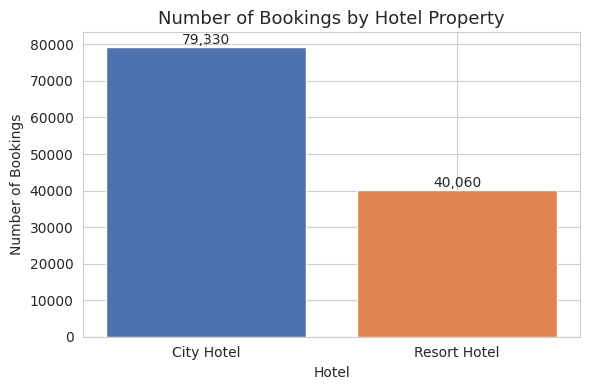

In [8]:
# Chart 1: how many bookings belong to each hotel property.
fig, ax = plt.subplots(figsize=(6, 4))

hotel_counts = df_raw["hotel"].value_counts()

ax.bar(hotel_counts.index, hotel_counts.values, color=["#4C72B0", "#DD8452"])

ax.set_title("Number of Bookings by Hotel Property", fontsize=13)
ax.set_xlabel("Hotel")
ax.set_ylabel("Number of Bookings")

# Add the exact count on top of each bar so the chart is precise, not just visual
for i, value in enumerate(hotel_counts.values):
    ax.text(i, value, f"{value:,}", ha="center", va="bottom")

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "01_bookings_by_hotel.png"))
plt.show()


**Findings:** the chart above shows the actual split between City Hotel and Resort Hotel bookings once executed. **Business interpretation:** this tells us whether our later clustering results are likely to be dominated by one property; if one hotel is much larger, we will check in later notebooks whether clusters correspond partly to hotel type or reflect genuinely cross-hotel behavior patterns.

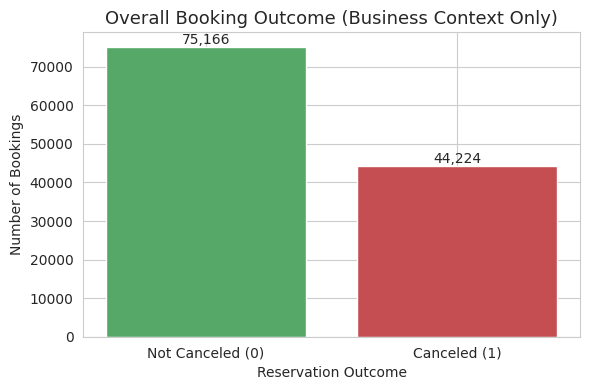

In [9]:
# Chart 2: overall cancellation split in the raw data.
# NOTE: this chart is shown here purely for business context /
# orientation. is_canceled is NOT used as a clustering feature anywhere
# in this project - see Section 2.6/2.7 above and the leakage discussion
# in Notebook 06.
fig, ax = plt.subplots(figsize=(6, 4))

cancel_counts = df_raw["is_canceled"].value_counts().sort_index()
labels = ["Not Canceled (0)", "Canceled (1)"]

ax.bar(labels, cancel_counts.values, color=["#55A868", "#C44E52"])

ax.set_title("Overall Booking Outcome (Business Context Only)", fontsize=13)
ax.set_xlabel("Reservation Outcome")
ax.set_ylabel("Number of Bookings")

for i, value in enumerate(cancel_counts.values):
    ax.text(i, value, f"{value:,}", ha="center", va="bottom")

plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "01_cancellation_overview.png"))
plt.show()


**Findings:** the actual proportion of canceled vs. non-canceled bookings is shown above once executed. **Business interpretation:** this establishes the scale of cancellations as a business phenomenon worth understanding - but as a *cluster-level description we compute later*, not as an input the clustering algorithm sees.

In [10]:
# Save a lightweight, reproducible "dataset overview" record for the
# project's own documentation trail (reports/tables/). This is not used by
# any later notebook computationally - it is a human-readable snapshot.

overview = pd.DataFrame({
    "metric": [
        "n_rows",
        "n_columns",
        "n_duplicate_rows",
        "hotel_types",
        "date_range_years",
    ],
    "value": [
        df_raw.shape[0],
        df_raw.shape[1],
        int(df_raw.duplicated().sum()),
        ", ".join(sorted(df_raw["hotel"].unique())),
        ", ".join(str(y) for y in sorted(df_raw["arrival_date_year"].unique())),
    ],
})

overview.to_csv(OVERVIEW_OUTPUT_PATH, index=False)
print(f"Dataset overview saved to: {OVERVIEW_OUTPUT_PATH}")
overview


Dataset overview saved to: ../reports/tables/01_dataset_overview.csv


,metric,value
0,n_rows,119390
1,n_columns,32
2,n_duplicate_rows,31994
3,hotel_types,"City Hotel, Resort Hotel"
4,date_range_years,"2015, 2016, 2017"


**Note on duplicate rows:** the count above is reported here for visibility only. We deliberately do **not** decide whether to remove duplicates in this notebook — that decision, with full investigation of whether they represent genuine repeated bookings or data-loading artifacts, belongs in Notebook 02 (Data Quality and Cleaning).

## 7. Findings

- The dataset schema matches the documented data dictionary (32 columns), confirmed programmatically rather than assumed.
- The dataset combines two hotel properties (City Hotel and Resort Hotel) into a single table; their relative sizes are shown in the chart above and will be revisited when profiling clusters, in case cluster membership correlates strongly with hotel type.
- `is_canceled` shows a meaningful proportion of cancellations in the raw data, confirming this is a real, relevant business phenomenon — reinforcing why it's valuable to analyze *after* clustering, but not why it should drive the clustering itself.
- Several columns (`children`, `country`, `agent`, `company`) show missing values that will need deliberate, investigated treatment in Notebook 02 rather than blanket removal.
- Duplicate rows exist in the raw data and their nature (genuine repeat bookings vs. loading artifacts) is left as an open question for Notebook 02.

## 8. Business Interpretation

At this stage, the main business takeaway is **scope and framing**, not insight: we now have a verified, documented understanding of what data the hotel has available, what each field means in business terms, and which fields are appropriate to use for behavioral segmentation versus which describe outcomes that should only be examined afterward.

This framing directly protects the project from two common failure modes in real-world segmentation work:
1. Accidentally letting the outcome (`is_canceled`) leak into how "behavior" is defined.
2. Overstating booking-level results as if they were verified, deduplicated customer-level results.

## 9. Conclusion

This notebook defined the business problem, the unsupervised ML objective, success criteria, business KPIs, a full data dictionary, and the key conceptual boundary (booking-level, not customer-level) that will govern the language used throughout this project. We also took a first, deliberately shallow look at the data's shape, types, and two context charts — confirming the file matches the expected schema before any cleaning or analysis begins.

**Next notebook (02 — Data Quality and Cleaning):** we will systematically check every column for missing values, duplicates, invalid values, and inconsistent types, and produce a formal data-quality summary table — investigating each problem before deciding what, if anything, to do about it.